## Multiple Regression Methods and other Models: Comparative Analysis
#### This notebook tests various regression algorithms and other models - on Temperature vs. Ice Cream Sales data
#### to evaluate which model generalizes best without overfitting.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# To ensure reproducibility
np.random.seed(42)

# Read data from Excel/CSV file
file_path = 'Ice_cream selling data.csv'
try:
    data = pd.read_csv(file_path)
except FileNotFoundError:
    print(f"Error: {file_path} not found. Please ensure the file is in the same directory.")
    # For demonstration, creating dummy data if file is missing
    temps = np.random.uniform(-5, 40, 200)
    sales = 50 + 10*temps - 0.1*(temps**2) + np.random.normal(0, 20, 200)
    data = pd.DataFrame({'Temperature (°C)': temps, 'Ice Cream Sales (units)': sales})

# Select features and target
x = data[['Temperature (°C)']].to_numpy()
y = data['Ice Cream Sales (units)'].to_numpy()

# Train/Test Split (70/30)
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

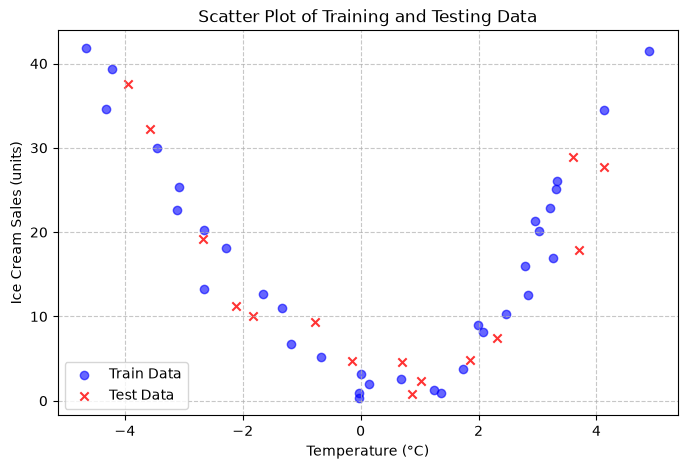

In [2]:
# Create the scatter plot to visualize the raw data distribution
plt.figure(figsize=(8, 5))

# Scatter plot for training data (blue circles)
plt.scatter(X_train, y_train, color='blue', label='Train Data', alpha=0.6, marker='o')

# Scatter plot for test data (red crosses)
plt.scatter(X_test, y_test, color='red', label='Test Data', alpha=0.8, marker='x')

# Add titles, labels, and legend
plt.title('Scatter Plot of Training and Testing Data')
plt.xlabel('Temperature (°C)')
plt.ylabel('Ice Cream Sales (units)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [3]:
# Note: Increase degree to 3 to capture non-linear relationships 
# and potentially observe overfitting in complex models.
poly = PolynomialFeatures(degree=3, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Standardization of the data (Crucial for SVR, KNN, and Neural Networks)
scaler = StandardScaler()
X_train_poly = scaler.fit_transform(X_train_poly)
X_test_poly = scaler.transform(X_test_poly)

# Save augmented data to CSVs
feature_names = poly.get_feature_names_out(['Temperature'])
augmented_train = pd.DataFrame(X_train_poly, columns=feature_names)
augmented_train['y'] = y_train
augmented_train.to_csv('augmented_train_data.csv', index=False)

augmented_test = pd.DataFrame(X_test_poly, columns=feature_names)
augmented_test['y'] = y_test
augmented_test.to_csv('augmented_test_data.csv', index=False)

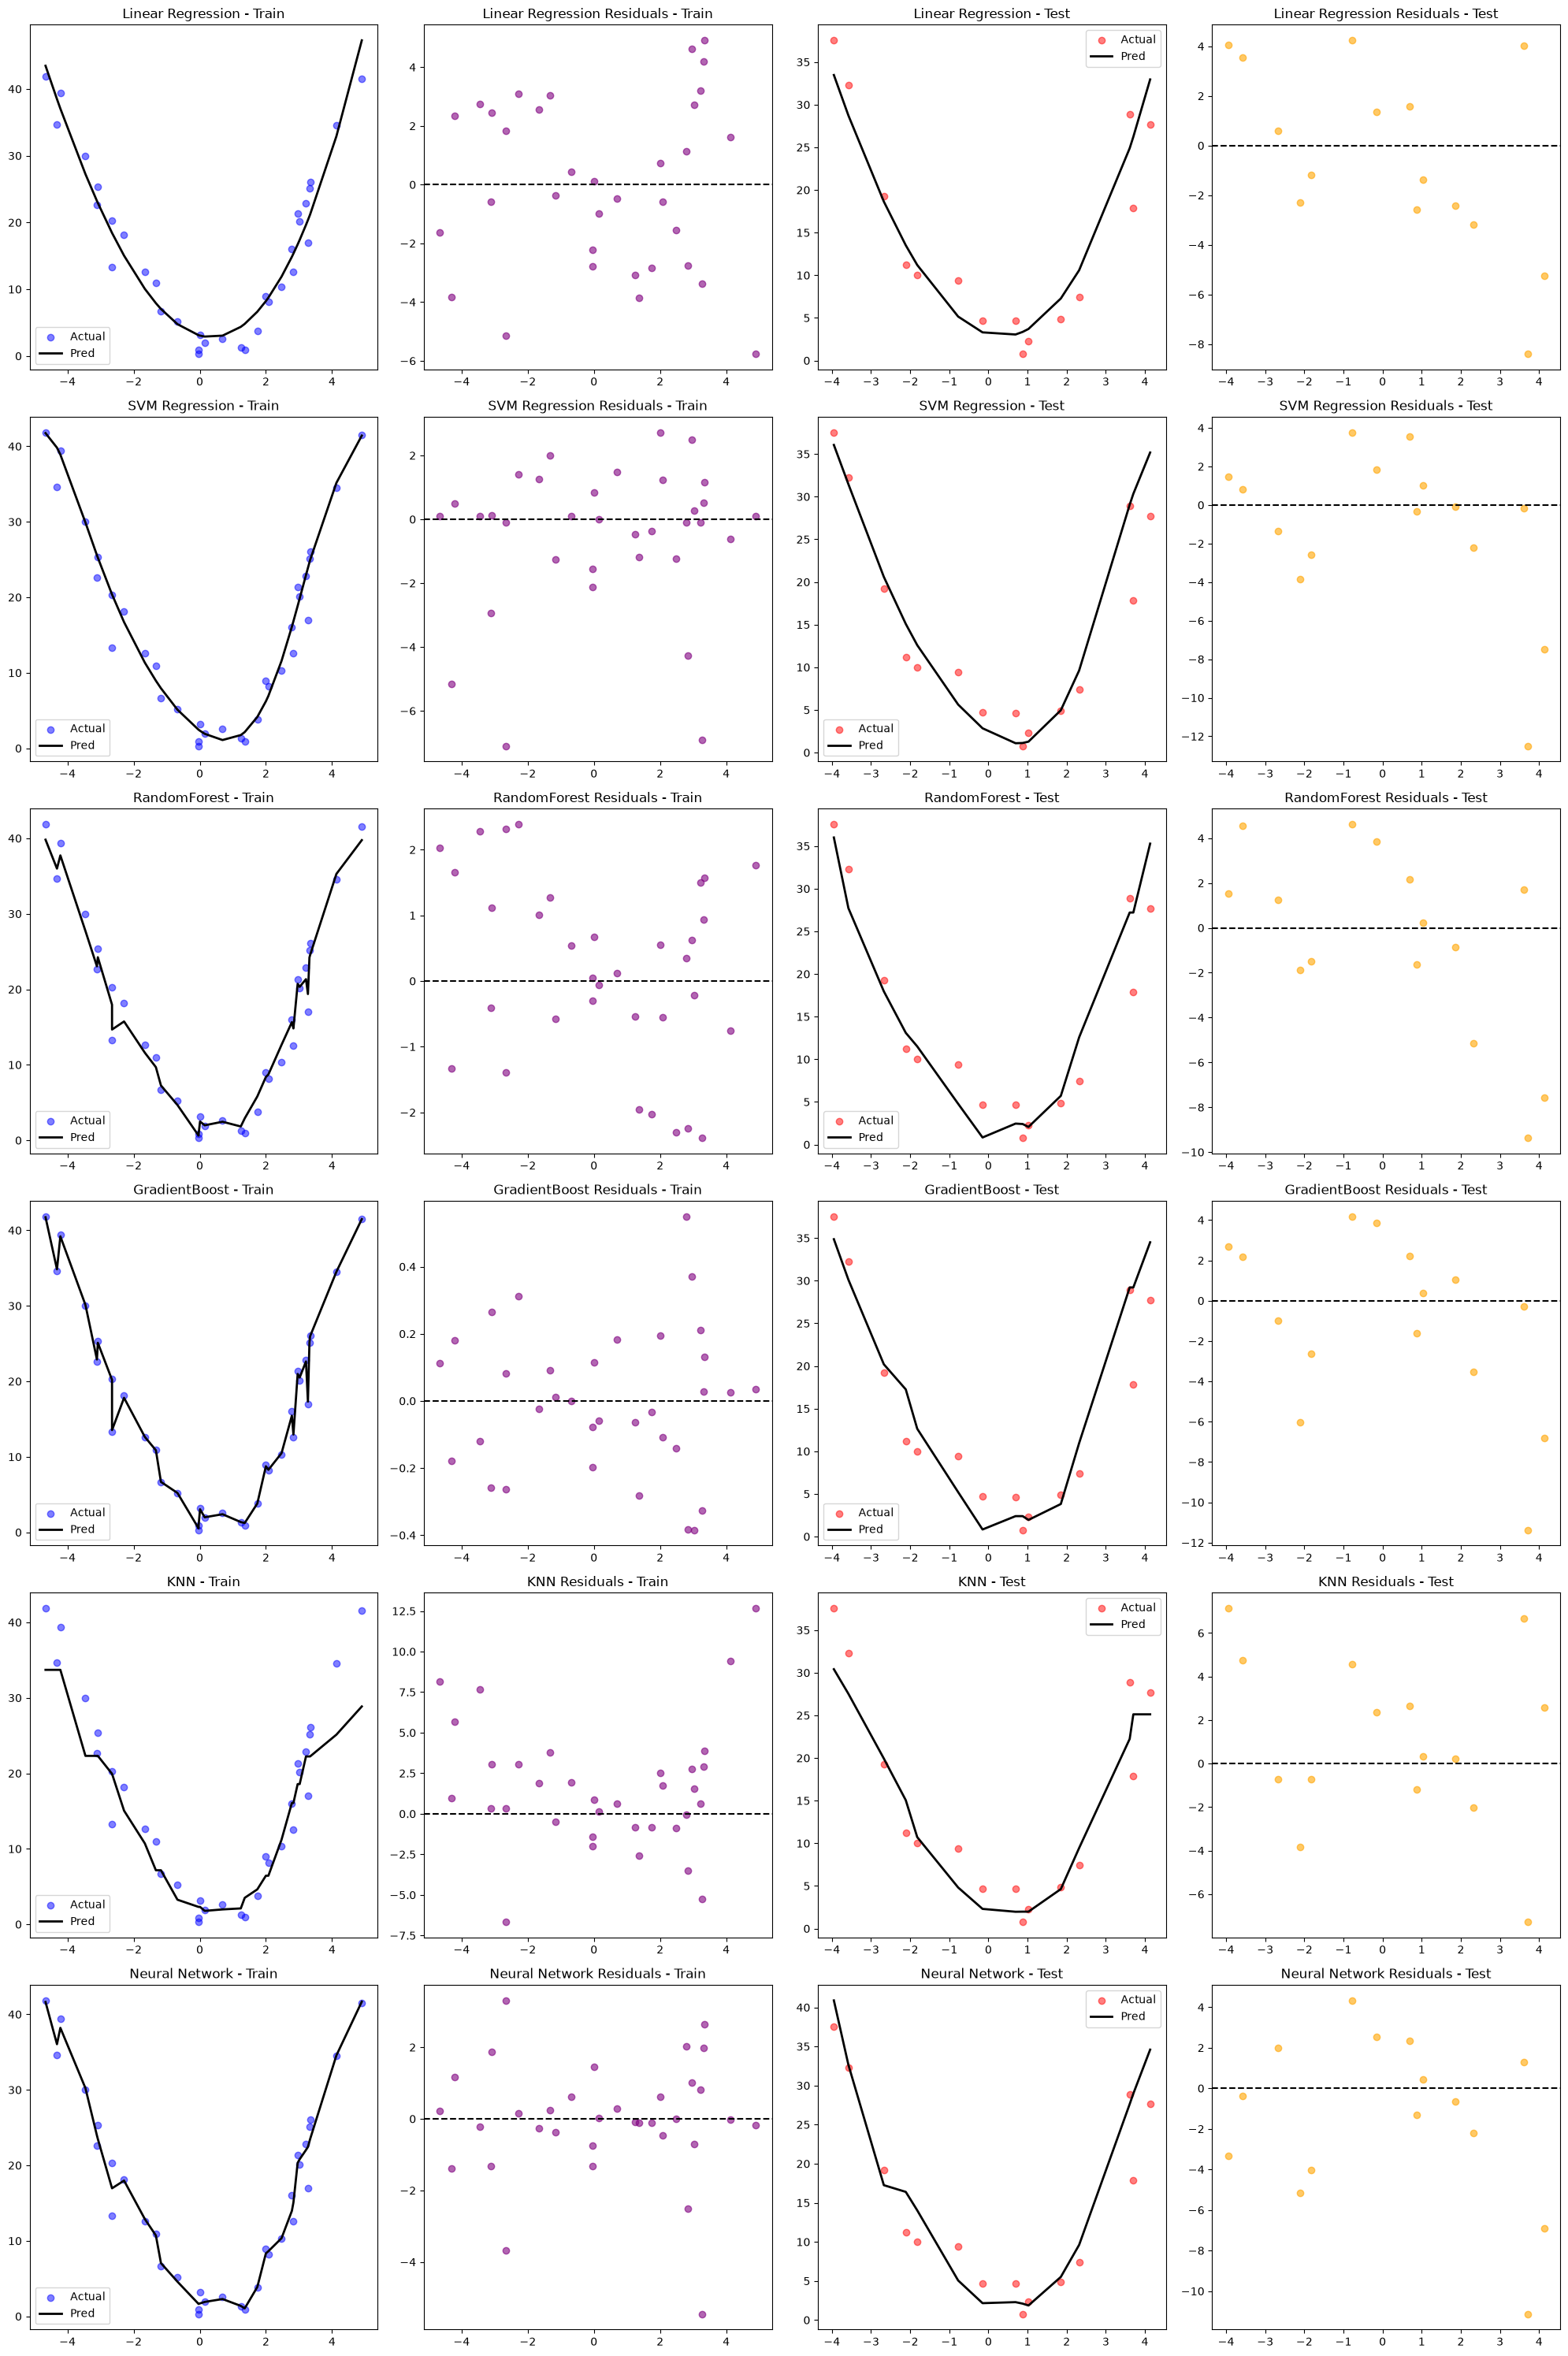

In [4]:

# Define algorithms dictionary
algorithms = {
    'Linear Regression': LinearRegression(),
    'SVM Regression': SVR(kernel='rbf', C=100, gamma=0.1), # RBF usually better for this than poly
    'RandomForest': RandomForestRegressor(random_state=42),
    'GradientBoost': GradientBoostingRegressor(random_state=42),
    'KNN': KNeighborsRegressor(n_neighbors=5),
    'Neural Network': MLPRegressor(hidden_layer_sizes=[50, 50], max_iter=5000, random_state=42),
}

# Metric tables
metric_table_train = pd.DataFrame()
metric_table_test = pd.DataFrame()

# Dictionary to store residuals for the next cell (prevents re-training)
residuals_dict = {}

# Create a grid of subplots for Predictions and Residuals
fig, axs = plt.subplots(len(algorithms), 4, figsize=(20, 5 * len(algorithms)))

for idx, (algorithm_name, algorithm) in enumerate(algorithms.items()):
    # 1. Train model
    algorithm.fit(X_train_poly, y_train)

    # 2. Predictions
    y_train_pred = algorithm.predict(X_train_poly)
    y_test_pred = algorithm.predict(X_test_poly)

    # 3. Calculate Metrics
    r2_train = r2_score(y_train, y_train_pred)
    rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
    
    r2_test = r2_score(y_test, y_test_pred)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

    # 4. Statistical Metrics (Statsmodels)
    res_train = y_train - y_train_pred
    res_test = y_test - y_test_pred
    
    # Store residuals for later plotting
    residuals_dict[algorithm_name] = {'train': res_train, 'test': res_test}

    dw_train = sm.stats.durbin_watson(res_train)
    jb_train, jb_p_train, _, _ = sm.stats.jarque_bera(res_train)
    
    dw_test = sm.stats.durbin_watson(res_test)
    jb_test, jb_p_test, _, _ = sm.stats.jarque_bera(res_test)

    # 5. Populate Metric Tables
    metric_table_train.loc[algorithm_name, ['R-squared', 'RMSE', 'Durbin-Watson', 'Jarque-Bera', 'JB P-value']] = \
        [r2_train, rmse_train, dw_train, jb_train, jb_p_train]
        
    metric_table_test.loc[algorithm_name, ['R-squared', 'RMSE', 'Durbin-Watson', 'Jarque-Bera', 'JB P-value']] = \
        [r2_test, rmse_test, dw_test, jb_test, jb_p_test]

    # 6. Plotting
    # Sort data for smoother scatter/line plotting
    sort_train_idx = np.argsort(X_train.flatten())
    sort_test_idx = np.argsort(X_test.flatten())

    # Train predictions
    axs[idx, 0].scatter(X_train, y_train, color='blue', alpha=0.5, label='Actual')
    axs[idx, 0].plot(X_train[sort_train_idx], y_train_pred[sort_train_idx], color='black', linewidth=2, label='Pred')
    axs[idx, 0].set_title(f"{algorithm_name} - Train")
    axs[idx, 0].legend()

    # Train Residuals
    axs[idx, 1].scatter(X_train, res_train, color='purple', alpha=0.6)
    axs[idx, 1].axhline(0, color='black', linestyle='--')
    axs[idx, 1].set_title(f"{algorithm_name} Residuals - Train")

    # Test predictions
    axs[idx, 2].scatter(X_test, y_test, color='red', alpha=0.5, label='Actual')
    axs[idx, 2].plot(X_test[sort_test_idx], y_test_pred[sort_test_idx], color='black', linewidth=2, label='Pred')
    axs[idx, 2].set_title(f"{algorithm_name} - Test")
    axs[idx, 2].legend()

    # Test Residuals
    axs[idx, 3].scatter(X_test, res_test, color='orange', alpha=0.6)
    axs[idx, 3].axhline(0, color='black', linestyle='--')
    axs[idx, 3].set_title(f"{algorithm_name} Residuals - Test")

plt.tight_layout()
plt.show()

In [5]:
# %%
# Display the metrics Tables
print("METRICS - TRAIN DATA:")
display(metric_table_train.round(4))
print("\n" + "="*80 + "\n")
print("METRICS - TEST DATA:")
display(metric_table_test.round(4))

METRICS - TRAIN DATA:


,R-squared,RMSE,Durbin-Watson,Jarque-Bera,JB P-value
Linear Regression,0.9463,2.8640,2.1832,1.5483,0.4611
SVM Regression,0.9632,2.3713,1.8521,14.7120,0.0006
RandomForest,0.9871,1.4008,2.1641,1.4579,0.4824
GradientBoost,0.9997,0.2144,1.9858,0.3262,0.8495
KNN,0.8860,4.1707,2.0771,3.8857,0.1433
Neural Network,0.9823,1.6455,2.1937,13.0921,0.0014




METRICS - TEST DATA:


,R-squared,RMSE,Durbin-Watson,Jarque-Bera,JB P-value
Linear Regression,0.9012,3.6241,1.7617,0.5642,0.7542
SVM Regression,0.8623,4.2771,1.1149,6.0097,0.0495
RandomForest,0.8749,4.0773,1.7563,1.4592,0.4821
GradientBoost,0.8569,4.3611,1.4700,1.9270,0.3815
KNN,0.8833,3.9376,1.8422,0.2793,0.8696
Neural Network,0.8652,4.2327,1.2144,1.5794,0.4540


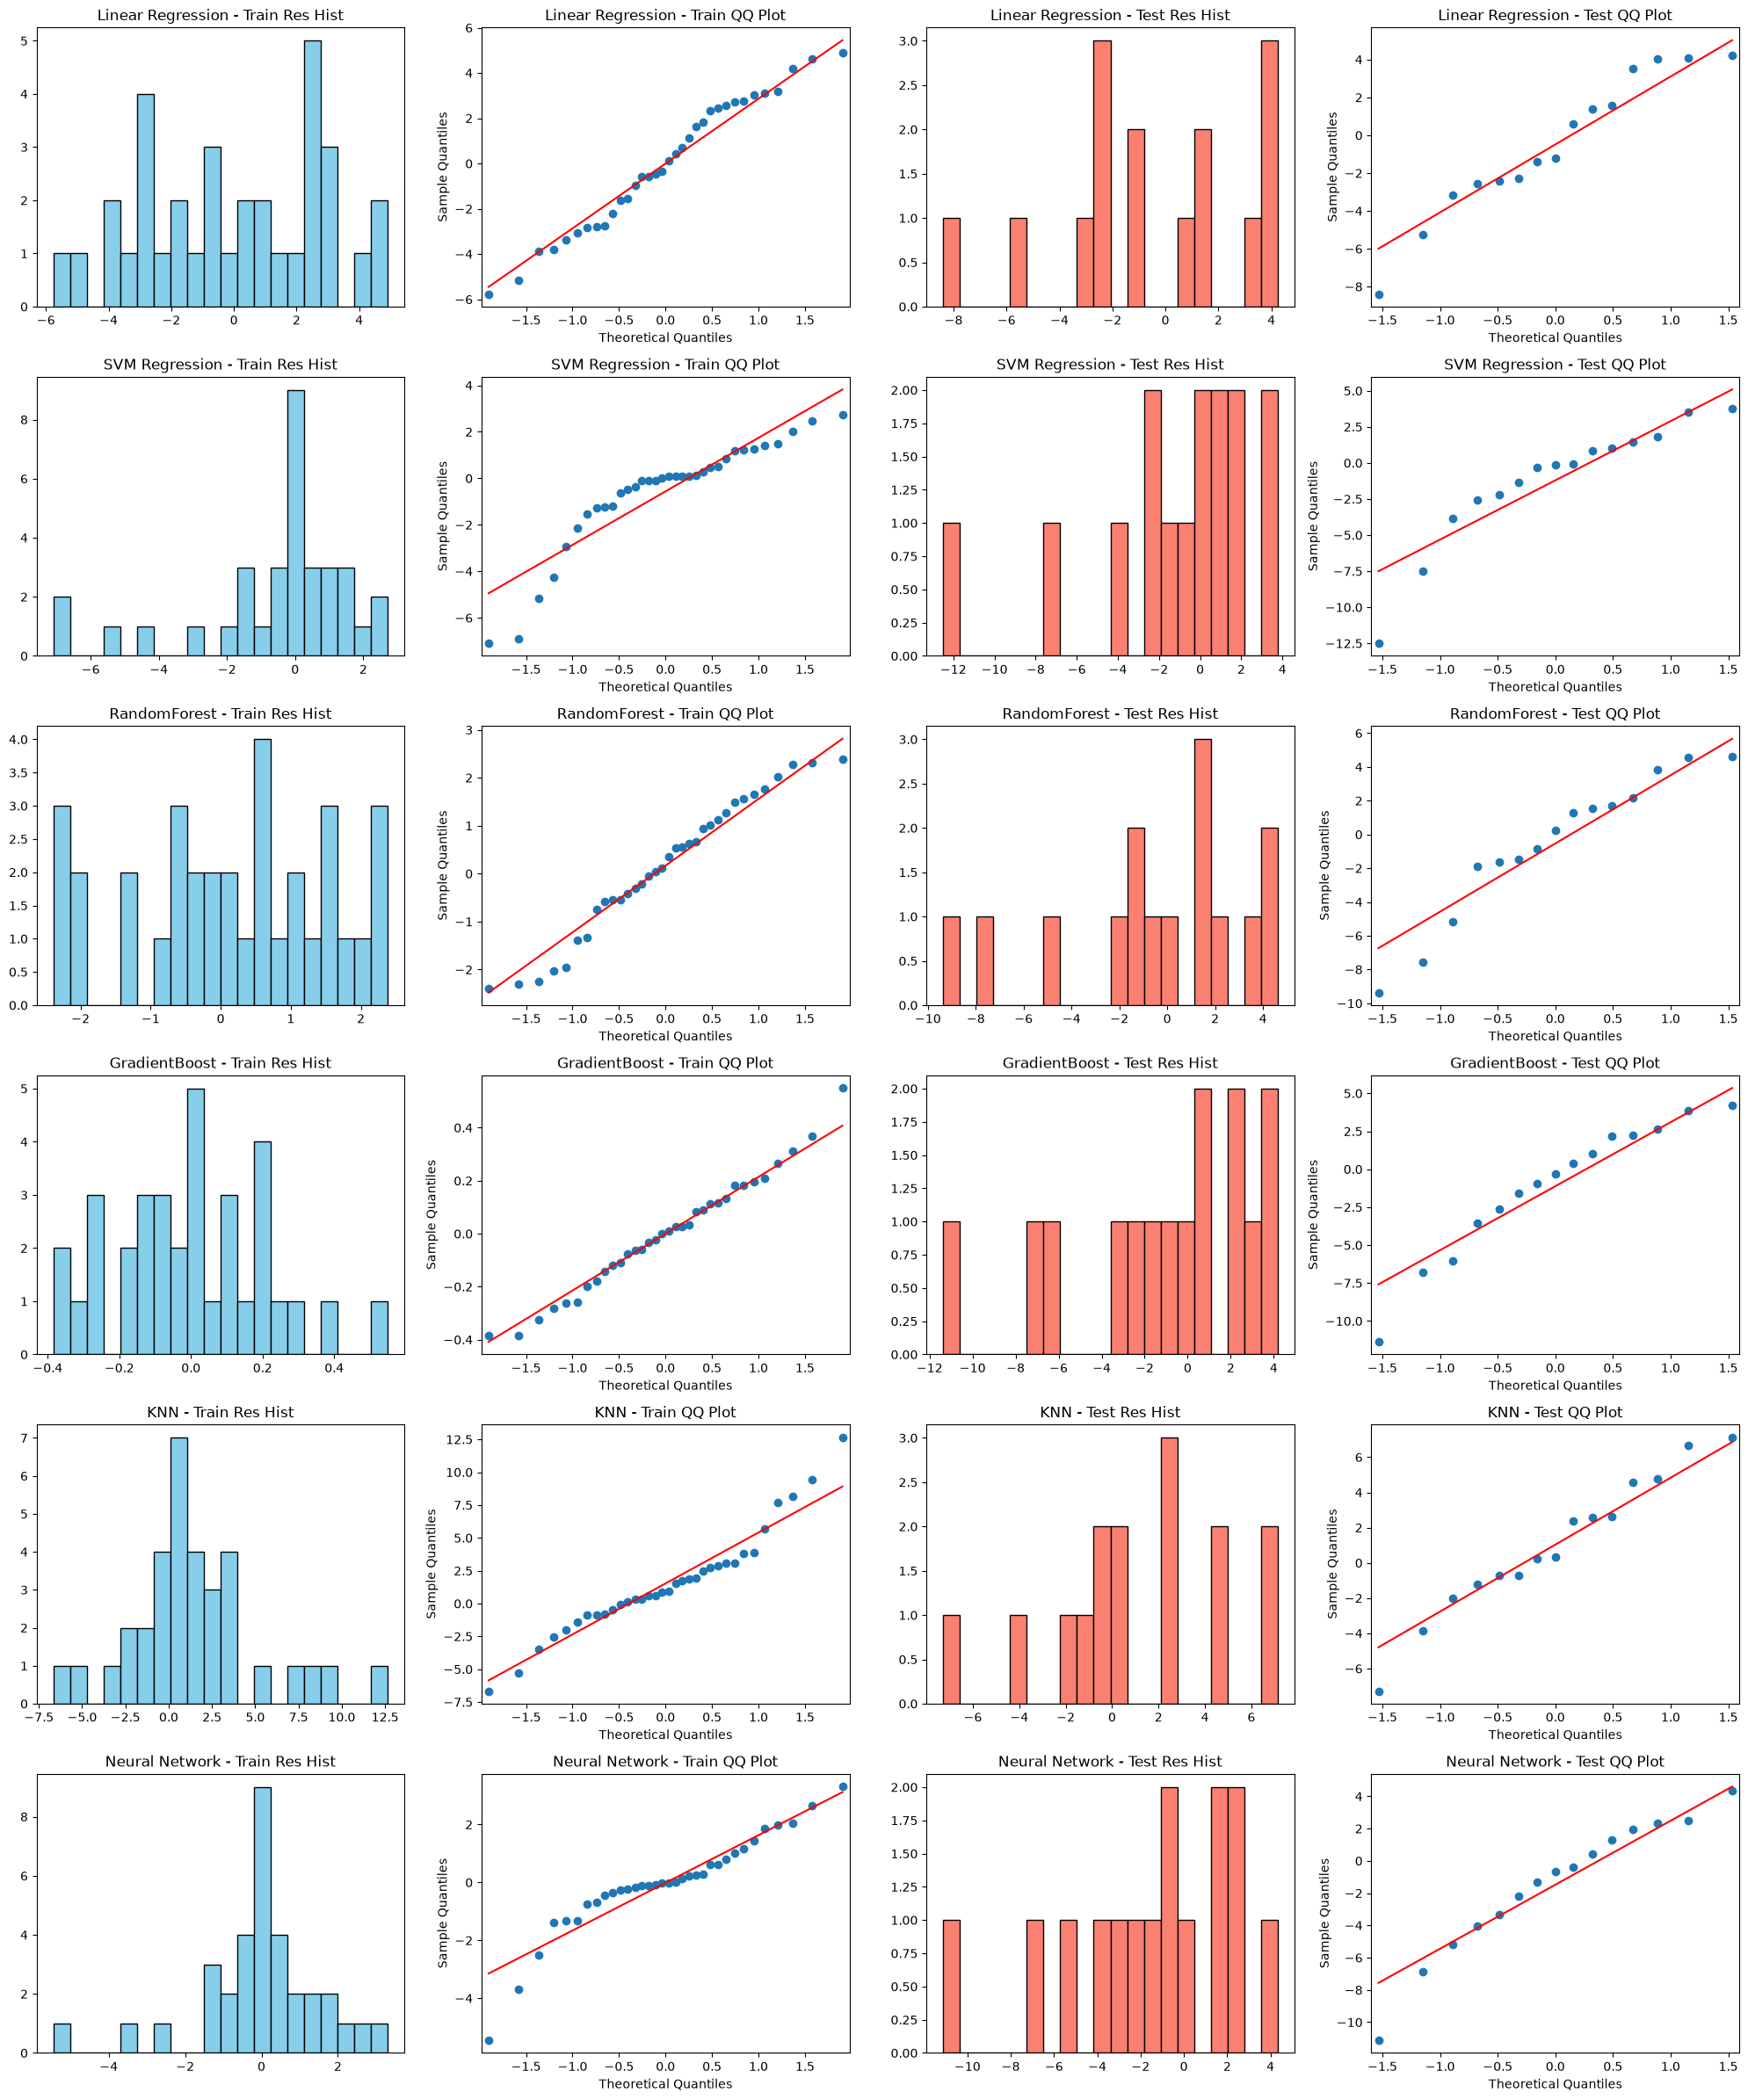

In [6]:
# %%
# Plotting Histograms and QQ-plots using the stored residuals
fig_residuals, axs_residuals = plt.subplots(len(algorithms), 4, figsize=(20, 4 * len(algorithms)))

for idx, (algo_name, res_data) in enumerate(residuals_dict.items()):
    
    res_train = res_data['train']
    res_test = res_data['test']

    # Train Histogram
    axs_residuals[idx, 0].hist(res_train, bins=20, edgecolor='black', color='skyblue')
    axs_residuals[idx, 0].set_title(f'{algo_name} - Train Res Hist')
    
    # Train QQ
    sm.qqplot(res_train, line='s', ax=axs_residuals[idx, 1])
    axs_residuals[idx, 1].set_title(f'{algo_name} - Train QQ Plot')

    # Test Histogram
    axs_residuals[idx, 2].hist(res_test, bins=20, edgecolor='black', color='salmon')
    axs_residuals[idx, 2].set_title(f'{algo_name} - Test Res Hist')

    # Test QQ
    sm.qqplot(res_test, line='s', ax=axs_residuals[idx, 3])
    axs_residuals[idx, 3].set_title(f'{algo_name} - Test QQ Plot')

plt.tight_layout()
plt.show()